# import majol and libraray

In [88]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM,SimpleRNN,Dense,Input
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt


In [89]:
#import data base
df = pd.read_csv("shahrekord_temperature.csv")
print(df.columns.tolist())
# Keep only the required columns
df = df[["time", "temperature_2m_mean "]].copy()

# Rename columns for easier coding
df.columns = ["date", "temperature"]
df

['time', 'temperature_2m_mean ', 'temperature_2m_max (°C)', 'temperature_2m_min (°C)', 'precipitation_sum (mm)', 'wind_speed_10m_max (km/h)', 'relative_humidity_2m_mean (%)']


,date,temperature
0,1/1/2025,-2.6
1,1/2/2025,-3.2
2,1/3/2025,-4.3
3,1/4/2025,-3.2
4,1/5/2025,-0.8
...,...,...
360,12/27/2025,-0.3
361,12/28/2025,-0.5
362,12/29/2025,-2.7
363,12/30/2025,-5.1


In [90]:
def create_sequences(data,seq_length):
    x,y=[],[]
    for i in range(len(data)-seq_length):
        x.append(data[i:i+seq_length])
        y.append(data[i+seq_length])
    return np.array(x),np.array(y)

In [91]:
seq_length=5
x,y=create_sequences(df.temperature,seq_length)
# 1. آماده‌سازی داده‌ها
x = np.asarray(x, dtype=np.float32).reshape(-1, seq_length, 1)
y = np.asarray(y, dtype=np.float32).reshape(-1, 1)

In [92]:
x

array([[[-2.6],
        [-3.2],
        [-4.3],
        [-3.2],
        [-0.8]],

       [[-3.2],
        [-4.3],
        [-3.2],
        [-0.8],
        [ 2.2]],

       [[-4.3],
        [-3.2],
        [-0.8],
        [ 2.2],
        [ 0.6]],

       ...,

       [[-1. ],
        [-0.4],
        [-0.8],
        [-0.3],
        [-0.5]],

       [[-0.4],
        [-0.8],
        [-0.3],
        [-0.5],
        [-2.7]],

       [[-0.8],
        [-0.3],
        [-0.5],
        [-2.7],
        [-5.1]]], shape=(360, 5, 1), dtype=float32)

In [93]:
y.shape

(360, 1)

In [94]:
model=Sequential(
   [Input(shape=(seq_length,1)),
    SimpleRNN(units=32,activation="tanh"),
    Dense(units=1)]
)

In [95]:
model.compile(optimizer='adam',loss='mse',metrics=['mae'])

In [96]:
#آموزش مدل 
#history_fit=model.fit(x,y,epochs=50, batch_size=32,verbose=1)

In [97]:
# 4. بررسی ابعاد
print("x:", x.shape)
print("y:", y.shape)
print("Input:", model.input_shape)


x: (360, 5, 1)
y: (360, 1)
Input: (None, 5, 1)


In [98]:
#از 365 روز اطلاعات 80 درصد برای آموزش و 20 درصد برای تست استفاده می کنیم 
temperature = df["temperature"].to_numpy(dtype=np.float32)

split_index = int(len(temperature) * 0.8)

train_data = temperature[:split_index]
test_data = temperature[split_index:]

print("Train size:", len(train_data))
print("Test size:", len(test_data))

Train size: 292
Test size: 73


In [99]:
#برای پیش‌بینی اولین روز آزمون، به دمای ۵ روز قبل از آن نیاز داریم. بنابراین، ۵ روز پایانی داده‌های آموزش را نیز به ورودی مجموعهٔ آزمون اضافه می‌کنیم
test_input = np.concatenate([
    train_data[-seq_length:],
    test_data
])
x_train,y_train=create_sequences(train_data, seq_length)
x_test, y_test = create_sequences(test_input, seq_length)
x_train = x_train.reshape(-1, seq_length, 1)
x_test = x_test.reshape(-1, seq_length, 1)

print("x_test:", x_test.shape)
print("y_test:", y_test.shape)
print("x_train:", x_train.shape)
print("y_train:", y_train.shape)

x_test: (73, 5, 1)
y_test: (73,)
x_train: (287, 5, 1)
y_train: (287,)


In [100]:
#آموزش مدل 
history_fit=model.fit(x_train,y_train,epochs=50, batch_size=32,verbose=1)

Epoch 1/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 289.4639 - mae: 14.5183
Epoch 2/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 272.0592 - mae: 14.0062 
Epoch 3/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 259.5546 - mae: 13.6369 
Epoch 4/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 248.5854 - mae: 13.3047 
Epoch 5/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 237.5839 - mae: 12.9747 
Epoch 6/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 225.3827 - mae: 12.5974 
Epoch 7/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 212.1817 - mae: 12.1856 
Epoch 8/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 199.2394 - mae: 11.7686 
Epoch 9/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 188.2833 - mae: 11.4043 
Epoch 10/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 179.1869 - mae: 11.1052 
Epoch 11/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 171.9212 - mae: 10.8607 
Epoch 12/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 165.8358 - mae: 10.6401 
Epoch 13/50
9/9 ━━━━━━━━━━

In [101]:
y_pred = model.predict(x_test)

y_pred = y_pred.flatten()
y_test = y_test.flatten()

print("Predicted:", y_pred[:10])
print("Actual:", y_test[:10])

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
Predicted: [13.896073  13.230764  13.4644375 13.215307  13.09976   13.266298
 13.167072  12.936726  12.789051  13.621492 ]
Actual: [12.5 12.7 12.4 12.2 12.4 12.3 12.  11.8 12.9 12.7]


In [102]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("MAE:", mae, "°C")
print("RMSE:", rmse, "°C")

MAE: 1.0082486867904663 °C
RMSE: 1.3387405702915998 °C


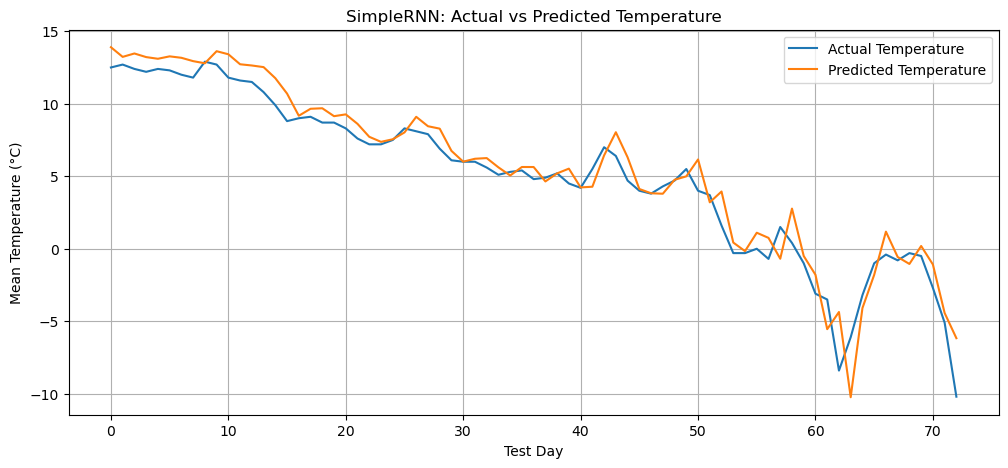

In [103]:

plt.figure(figsize=(12, 5))

plt.plot(y_test, label="Actual Temperature")
plt.plot(y_pred, label="Predicted Temperature")

plt.xlabel("Test Day")
plt.ylabel("Mean Temperature (°C)")
plt.title("SimpleRNN: Actual vs Predicted Temperature")
plt.legend()
plt.grid(True)
plt.show()

In [104]:
baseline_pred = temperature[split_index - 1:-1]

baseline_mae = mean_absolute_error(
    temperature[split_index:],
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        temperature[split_index:],
        baseline_pred
    )
)

print(f"Baseline MAE: {baseline_mae:.2f} °C")
print(f"Baseline RMSE: {baseline_rmse:.2f} °C")

print(f"SimpleRNN MAE: {mae:.2f} °C")
print(f"SimpleRNN RMSE: {rmse:.2f} °C")

Baseline MAE: 0.85 °C
Baseline RMSE: 1.30 °C
SimpleRNN MAE: 1.01 °C
SimpleRNN RMSE: 1.34 °C
